Hesaplama tamamlandı.
En büyük eksenel kuvvet:-621111.11
En küçük eksenel kuvvet:-1487500.00
En büyük moment: 524125000.00
En küçük moment: 456981481.48


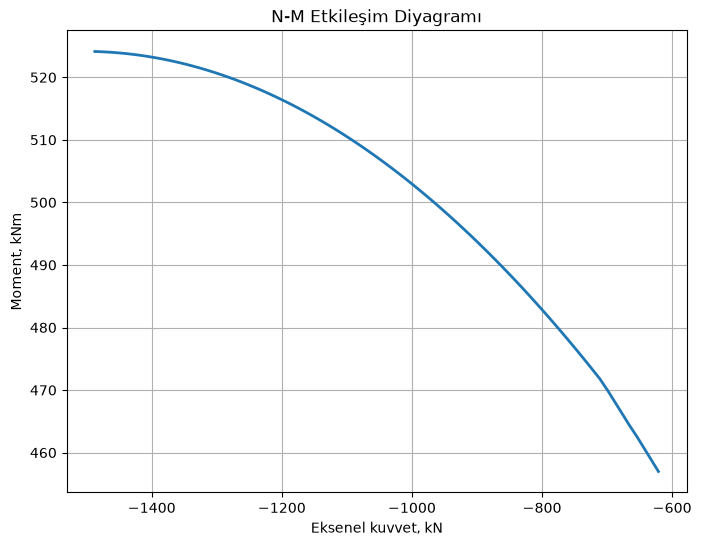

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# -----------------------------------------------
# Malzeme fonksiyonları
# -----------------------------------------------

def steel_stress_strain(eps, Es=200000, fy=420):
    """
    Çelik için gerilme-şekil değiştirme ilişkisi.
    
    Parametreler:
    eps : Gerinim
        Şekil değiştirme (strain) değeri.
    Es : Elastisite modülü, MPa
        Çeliğin elastik modülü (default: 200000 MPa).
    fy : Akma gerilmesi, MPa
    """
    sigma = Es * eps

    # Gerilme fy ve -fy sınırları arası 

    sigma = Es * eps
    sigma = np.clip(sigma, -fy, fy)     

    return sigma

def comp_stress_strain(eps, fcd=20):
    """
    Beton için gerilme-şekil değiştirme ilişkisi.
    
    Parametreler:
    eps : Gerinim
        Şekil değiştirme (strain) değeri.
    fcd : Betonun tasarım basınç dayanımı, MPa
        Betonun tasarım basınç dayanımı (default: 20 MPa)
    
    Beton basınç gerinimini gerilmeye dönüştürür
    Basit sabit gerilme modeli kullanılmıştır.

    eps : Beton gerinimi
    fcd : Tasarım beton basınç dayanımı
    """

    sigma = np.zeros_like(eps)

    # Beton yalnızca basınçta gerilme taşır
    compression = eps < 0
    sigma[compression] = -fcd

    return sigma

#-----------------------------------------------
# Kesit ve malzeme bilgileri
# ----------------------------------------------

b = 300  # Kesit genişliği, mm
h = 500   # Kesit yüksekliği, mm
d = 450  # Etkin yükseklik, mm
c = 50   # Donatı konumu, mm
As1 = 2000  # Donatı alanı
As2 = 2000  # Donatı alanı
""
a=h

eps_cu = -0.0035 # Beton nihai basınç gerinimi
eps_su = 0.01    # Çelik gerinimi
eps_y = 0.0025   # Çeliğin akma birim şekil değiştirmesi
n_step = 100 

#-----------------------------------------------
# Nötr eksen değerleri
#----------------------------------------------
yn_sup=-d*eps_cu/(eps_su-eps_cu)
yn_inf=-d*eps_cu/(eps_y-eps_cu)
yn=np.linspace(yn_sup, yn_inf, n_step)
psi=-eps_cu / yn
eps_s1=-psi*(yn-d)
eps_s2=-psi*(yn-c)
eps_s1=np.round(eps_s1, 5)
eps_s2=np.round(eps_s2, 5)
sig_s1=steel_stress_strain(eps_s1)
sig_s2=steel_stress_strain(eps_s2)

Nc=np.zeros(n_step)
Mc=np.zeros(n_step)
for i in range(n_step):
    y=np.linspace(0, yn[i], 10)

    eps_c=-(yn[i]-y)*psi[i]
    eps_c=np.round(eps_c, 7)
    sig_c = comp_stress_strain(eps_c)

    Nc[i]=b*np.trapezoid(sig_c, y)

    denominator = np.trapezoid(sig_c, y)
    if abs(denominator) > 1e-12:
        ygc = np.trapezoid(sig_c * y, y) / denominator
    else:
        ygc = 0
    Mc[i]=Nc[i]*(a/2-ygc)
Nrd_3=Nc+As1*sig_s1+As2*sig_s2
Mrd_3=-Mc+As1*sig_s1*(a/2-c)-As2*sig_s2*(a/2-c)

#-----------------------------------------------
# Sonuçların yazdırılması
# ----------------------------------------------

print("Hesaplama tamamlandı.")
print(f"En büyük eksenel kuvvet:{np.max(Nrd_3):.2f}")
print(f"En küçük eksenel kuvvet:{np.min(Nrd_3):.2f}")
print(f"En büyük moment: {np.max(Mrd_3):.2f}")
print(f"En küçük moment: {np.min(Mrd_3):.2f}")

#------------------------------------------------
# N-M etkileşim grafiği
#------------------------------------------------

plt.figure(figsize=(8,6))

plt.plot(Nrd_3 / 1000, Mrd_3 / 1e6, linewidth=2)

plt.xlabel("Eksenel kuvvet, kN")
plt.ylabel("Moment, kNm")
plt.title("N-M Etkileşim Diyagramı")
plt.grid(True)

plt.show()


In [3]:
import sys
!{sys.executable} -m pip install numpy matplotlib

   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   --- ------------------------------------ 1.0/12.7 MB 6.2 MB/s eta 0:00:02
   --------- ------------------------------ 3.1/12.7 MB 7.6 MB/s eta 0:00:02
   -------------- ------------------------- 4.7/12.7 MB 7.5 MB/s eta 0:00:02
   ------------------- -------------------- 6.3/12.7 MB 7.7 MB/s eta 0:00:01
   ------------------------- -------------- 8.1/12.7 MB 7.7 MB/s eta 0:00:01
   ------------------------------ --------- 9.7/12.7 MB 7.7 MB/s eta 0:00:01
   ------------------------------------ --- 11.5/12.7 MB 7.8 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 7.6 MB/s  0:00:01
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 7.4 MB/s eta 0:00:02
   ----------- ---------------------------- 2.6/9.5 MB 7.7 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.5 MB 6.9 MB/s eta 0:00:01
   ---------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
